# HOMEWORK 9

In this homework, you are going to use the dlib face detector and apply it to an image of your liking. You can follow the procedure shown in lesson 9. Please always comment your code so I can see what you're doing :-)

For this homework we are not going to provide you with any code, you'll have to build the face detector on your own.

### Step 0

Run the necessary imports.

In [1]:
# Бібліотеки: OpenCV для зображень, dlib для детектора облич, numpy для масивів, matplotlib для графіків
import cv2
import dlib
import numpy as np
from matplotlib import pyplot as plt

plt.rcParams['figure.figsize'] = [15, 10]   # більший розмір графіків

### Step 1

Load an image (any image that contains faces).

In [2]:
# OpenCV читає зображення в порядку BGR, а matplotlib очікує RGB
img = cv2.imread('../data/large_preview.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Детектор працює із зображенням у відтінках сірого
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

### Step 2

Load the dlib face predictor.

In [3]:
# Готовий натренований dlib-детектор облич (фронтальних)
detector = dlib.get_frontal_face_detector()

### Step 3

Run the predictor on your image.

In [4]:
# Запускаємо детектор; 1 = збільшуємо зображення один раз, щоб знайти дрібніші обличчя
rects = detector(gray, 1)
print('Number of detected faces:', len(rects))

Number of detected faces: 72


### Step 4

Draw bounding boxes around the detected faces and plot the image. Use different colour for each face.

(np.float64(-0.5), np.float64(2559.5), np.float64(2559.5), np.float64(-0.5))

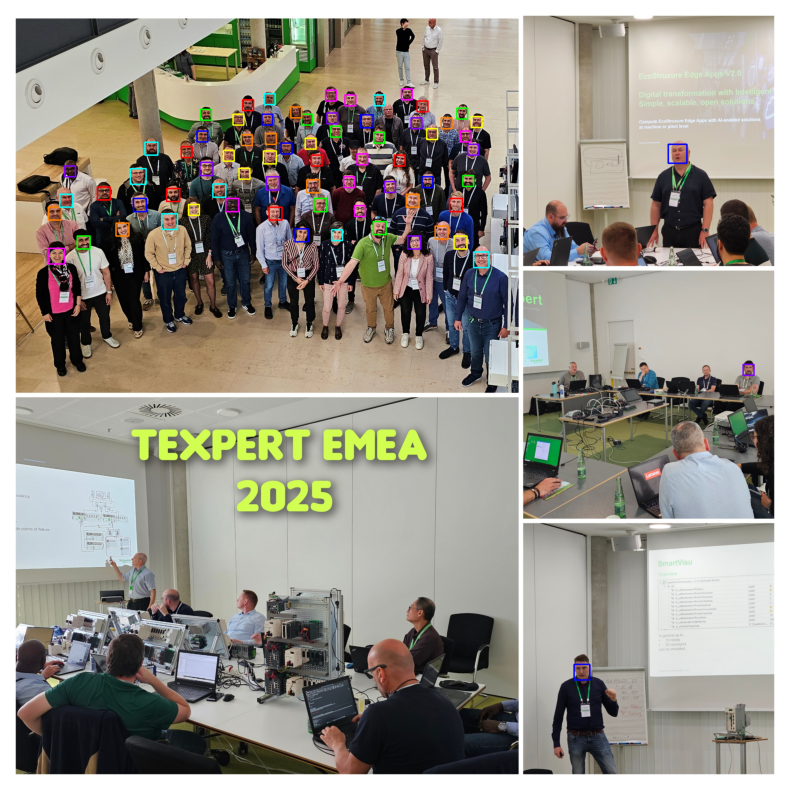

In [5]:
# Один колір (R, G, B) на кожне обличчя; якщо облич більше за кольори, кольори повторюються
colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0),
          (255, 0, 255), (0, 255, 255), (255, 128, 0), (128, 0, 255)]

result = np.copy(img)   # малюємо на копії, оригінал не чіпаємо
for i, rect in enumerate(rects):
    # прямокутник dlib (left, top, right, bottom) -> формат OpenCV (x, y, w, h)
    x, y = rect.left(), rect.top()
    w, h = rect.right() - x, rect.bottom() - y
    # i % len(colors) бере кольори по колу зі списку
    cv2.rectangle(result, (x, y), (x + w, y + h), colors[i % len(colors)], 3)

plt.imshow(result)
plt.axis(False)

### Step 5 (optional)

Repeat the process with a different and more challenging image (more faces, smaller faces, people with glasses, hats, helmets, etc.). How does the detector perform? Is it robust?
--
Загалом я взяв картинку і так доволі непросту з великою кількістю малих обличь, з окулярами і тд. Загалом він розпізнав майже всі обличчя, окрім тих які дуже дрібні чи які прямо дивляться в камеру і відповідають його вимогам.